<a href="https://colab.research.google.com/github/nickkraus52/MachineLearning/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Load the dataset into a Pandas DataFrame.

The following code segments import the ucimlrepo python package needed to import the required dataset. Then I import the required modules needed to initialize and store the dataset into a Panda Dataframe. Finally, I display the dataframe head to smoketest that the dataframe is loaded in as the properly.

In [146]:
!pip install ucimlrepo

In [147]:
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

heart_disease = fetch_ucirepo(id=45)
df = heart_disease.data.features.copy()
df['target'] = heart_disease.data.targets.copy()

print('First 5 Elements:')
display(df.head())

First 5 Elements:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## Inspecting the Dataset

I ran the info function on the Dataframe to see the columns and their datatypes. I recognized that all the columns were numerical data types, so no implicit missing values. I also ran the describe and value_counts functions to see which columns might be categorical features.

In [148]:
print('Column Names and Data Types:')
display(df.info())

print('\nData Statistical Distribution: ')
display(df.describe().T)

Column Names and Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


None


Data Statistical Distribution: 


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [149]:
display(df['sex'].value_counts())
display(df['exang'].value_counts())
display(df['ca'].value_counts())
display(df['slope'].value_counts())
display(df['restecg'].value_counts())
display(df['thal'].value_counts())

,count
sex,
1,206
0,97


,count
exang,
0,204
1,99


,count
ca,
0.0,176
1.0,65
2.0,38
3.0,20


,count
slope,
1,142
2,140
3,21


,count
restecg,
0,151
2,148
1,4


,count
thal,
3.0,166
7.0,117
6.0,18


## Imputing Missing or Implicit Values
The method I used to import the dataset had every column imported as a numerical type with nulls already included. Because of this I had no need to check for '?' string implicit missing values. Although there were a few categorical columns that needed to be converted from int and float types. I also then altered the target column so that it could be easily classified. I changed any value greater than 0 to 1 so the column would be binary.

In [150]:
print('Values with ?: ')
display((df == '?').sum())

print('\nNull Values: ')
display(df.isnull().sum())


Values with ?: 


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Null Values: 


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [151]:
display(df['target'].value_counts())

print('\nSetting the Target to Binary values, with any value above 1 set to 1')
df["target"] = (df["target"] > 0).astype(int)

display(df['target'].value_counts())


,count
target,
0,164
1,55
2,36
3,35
4,13



Setting the Target to Binary values, with any value above 1 set to 1


,count
target,
0,164
1,139


In [152]:
from pandas.core.arrays import categorical
from sklearn.impute import SimpleImputer

cat_imputer = SimpleImputer(strategy='most_frequent')
num_imputer = SimpleImputer(strategy='median')

num_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
cat_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

sample_cat = cat_imputer.fit_transform(df[cat_features])
sample_num = num_imputer.fit_transform(df[num_features])

sampleDF = pd.DataFrame(sample_cat, columns=cat_features)
sampleDF[num_features] = sample_num

print('\nNull Values: ')
display(sampleDF.isnull().sum())


Null Values: 


,0
sex,0
cp,0
fbs,0
restecg,0
exang,0
slope,0
ca,0
thal,0
age,0
trestbps,0


## Building a Pipeline with Encoding and Scaling

I then import the modules to create the pipeline for both numerical and categorical features. I combine them into a single column transformer. I used the simple imputer with median strategy and a standard scaler for the numerical pipeline. I used a simple imputer with most frequent strategy and the one hot encoder for the categorical features.

In [153]:
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('standardize', StandardScaler())
])

cat_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

preprocessing = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
])

display(preprocessing)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('standardize',
                                                  StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak']),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'cp', 'fbs', 'restecg', 'exang',
                                  'slope', 'ca', 'thal'])])

## Creating and Training the Support Vector Classifier

First I imported all the necessary metrics and modules for splitting the data and analyzing it with different models. I created a function that will take in a model and the test data. This function is used to to find the Confusion Matrix, ROC AUC Score, and the Classification Report. I then split the dataset into X and y, then split between test and training data. This data is then used to test a Support Vector Classifier with kernel set to rbf and probability set to true.

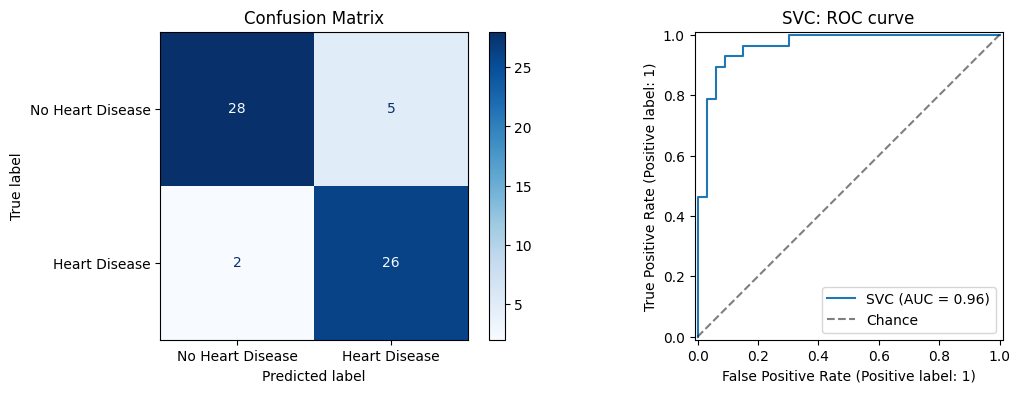


Classification Report for SVC:
                  precision    recall  f1-score   support

No Heart Disease       0.93      0.85      0.89        33
   Heart Disease       0.84      0.93      0.88        28

        accuracy                           0.89        61
       macro avg       0.89      0.89      0.89        61
    weighted avg       0.89      0.89      0.89        61



In [154]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from matplotlib import pyplot as plt
from sklearn.base import clone

models = {}

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].set_title('Confusion Matrix')
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['No Heart Disease', 'Heart Disease']).plot(ax=axes[0], cmap='Blues')

    auc = roc_auc_score(y_test, y_proba)
    RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name=f"{name}")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Chance")
    axes[1].set_title(f"{name}: ROC curve")
    axes[1].legend(loc="lower right")
    plt.show()

    report = classification_report(y_test, y_pred, target_names=['No Heart Disease', 'Heart Disease'], output_dict=True)

    print(f'\nClassification Report for {name}:')
    print(classification_report(y_test, y_pred, target_names=['No Heart Disease', 'Heart Disease']))

    models[name] = {
        'Accuracy': report['accuracy'],
        'Precision': report['Heart Disease']['precision'],
        'Recall': report['Heart Disease']['recall'],
        'F1 Score': report['Heart Disease']['f1-score'],
        "ROC-AUC": auc
    }

X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

SVC_model = Pipeline([
    ('preprocessing', clone(preprocessing)),
    ('clf', SVC(kernel='rbf', probability=True, random_state=42))
])

SVC_model.fit(X_train, y_train)
evaluate_model('SVC', SVC_model, X_test, y_test)





## Decision Tree Classifier Training and Evaluation

Building my decision tree classifier I used my preprocessing pipeline and added my classifier to the end of the pipeline. I then fit my model and ran the function I created earlier to visualize the accuracy of this model. I then compared both classifiers' results to see that the SVC model had a higher F1 score and ROC AUC and overall was more accurate.

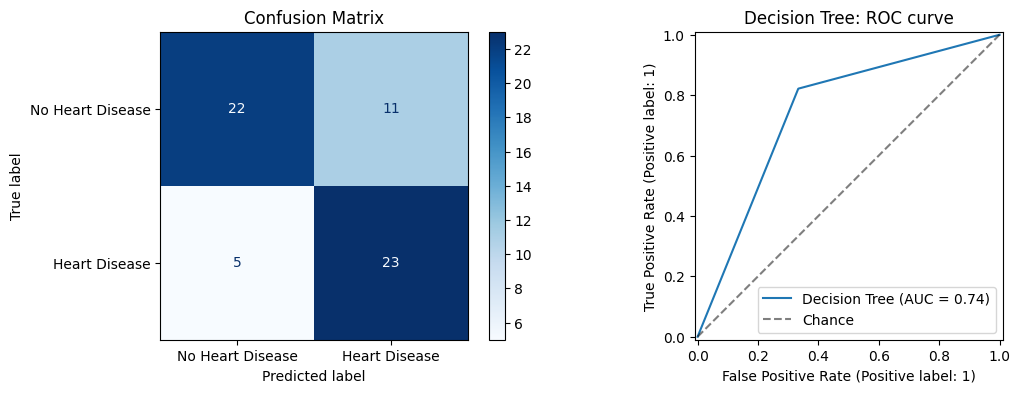


Classification Report for Decision Tree:
                  precision    recall  f1-score   support

No Heart Disease       0.81      0.67      0.73        33
   Heart Disease       0.68      0.82      0.74        28

        accuracy                           0.74        61
       macro avg       0.75      0.74      0.74        61
    weighted avg       0.75      0.74      0.74        61



In [155]:
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

DT_model = Pipeline([
    ('preprocessing', clone(preprocessing)),
    ('clf', DecisionTreeClassifier(random_state=42))
])

DT_model.fit(X_train, y_train)
evaluate_model('Decision Tree', DT_model, X_test, y_test)

In [156]:
print('Analysis Metrics of SVC Vs. Decision Tree Classifier')
pd.DataFrame(models).T.sort_values(by='F1 Score', ascending=False)

Analysis Metrics of SVC Vs. Decision Tree Classifier


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
SVC,0.885246,0.838710,0.928571,0.881356,0.964286
Decision Tree,0.737705,0.676471,0.821429,0.741935,0.744048


## Testing Hyperparameters using GridSearchCV

I set up a dictionary of C and Gamma values as the two hyperparameters I tested with. I then used StratifiedKFold to split sets into shuffled K Folds. Then I run the GridSearchCV model with ROC AUC as the targeted scoring metric. With the Grid Search I determined the best Gamma and C values within the potential parameters that maxamizes ROC AUC. I then I displayed the metrics of this model using the function I created earlier. Finally I created a heatmap comparing C and Gamma to show which values were most accurate. The lower the Gamma and the higher the C showed the most accurate results. Higher C values mean less regularization which risks overfitting, but lower gamma values smooth decision boundaries and can cause underfitting. It seems the balance of both creates a well fitted model.

Best Parameters: C=10000, gamma=1e-05


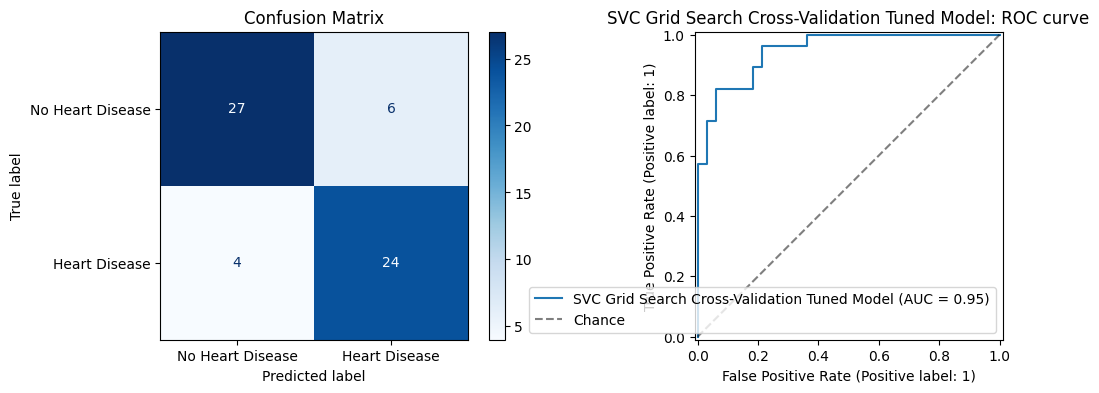


Classification Report for SVC Grid Search Cross-Validation Tuned Model:
                  precision    recall  f1-score   support

No Heart Disease       0.87      0.82      0.84        33
   Heart Disease       0.80      0.86      0.83        28

        accuracy                           0.84        61
       macro avg       0.84      0.84      0.84        61
    weighted avg       0.84      0.84      0.84        61



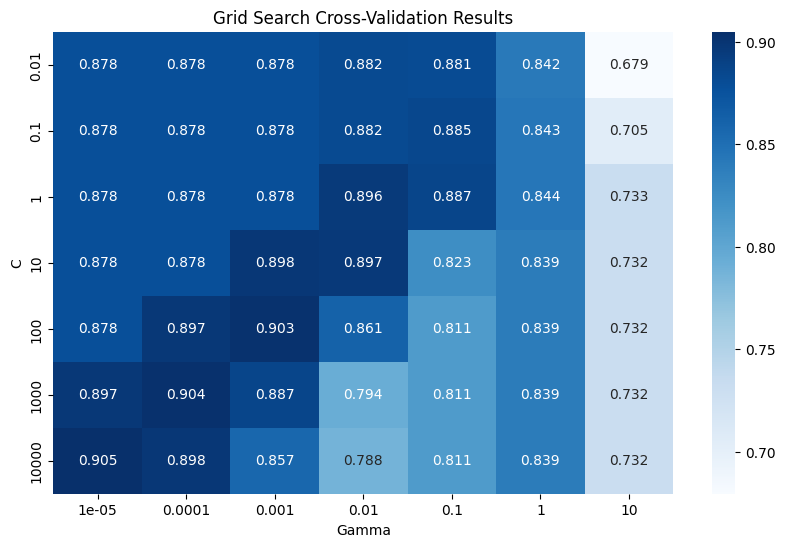

In [157]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import seaborn as sns

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    'clf__C': [0.01, 0.1, 1, 10, 100, 1000, 10000],
    'clf__gamma': [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]
}

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

grid = GridSearchCV(SVC_model, param_grid, cv=cv, n_jobs=-1, scoring='roc_auc')
grid.fit(X_train, y_train)

C = grid.best_params_['clf__C']
gamma = grid.best_params_['clf__gamma']

print(f'Best Parameters: C={C}, gamma={gamma}')
best_model = grid.best_estimator_
evaluate_model(f'SVC Grid Search Cross-Validation Tuned Model', best_model, X_test, y_test)

scores = grid.cv_results_['mean_test_score'].reshape(len(param_grid['clf__C']), len(param_grid['clf__gamma']))

plt.figure(figsize=(10, 6))
sns.heatmap(scores, cmap='Blues', fmt='.3f', annot=True, xticklabels=param_grid['clf__gamma'], yticklabels=param_grid['clf__C'])
plt.xlabel('Gamma')
plt.ylabel('C')
plt.title('Grid Search Cross-Validation Results')
plt.show()

In [158]:
print('Analysis Metrics of SVC Vs. Decision Tree Classifier Vs. Hyperparameter Tuned SVC')
pd.DataFrame(models).T.sort_values(by='F1 Score', ascending=False)

Analysis Metrics of SVC Vs. Decision Tree Classifier Vs. Hyperparameter Tuned SVC


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
SVC,0.885246,0.838710,0.928571,0.881356,0.964286
SVC Grid Search Cross-Validation Tuned Model,0.836066,0.800000,0.857143,0.827586,0.948052
Decision Tree,0.737705,0.676471,0.821429,0.741935,0.744048


## Generating a Decision Tree Visualization

With this code cell I chose to visualize the decision tree using plot_tree. I first got the feature names and cleaned them up, removing num or cat associated with the feature name. I then displayed the tree with a max depth of 4 as the tree quickly gets cluttered and hard to read with the more levels of the tree that are displayed.

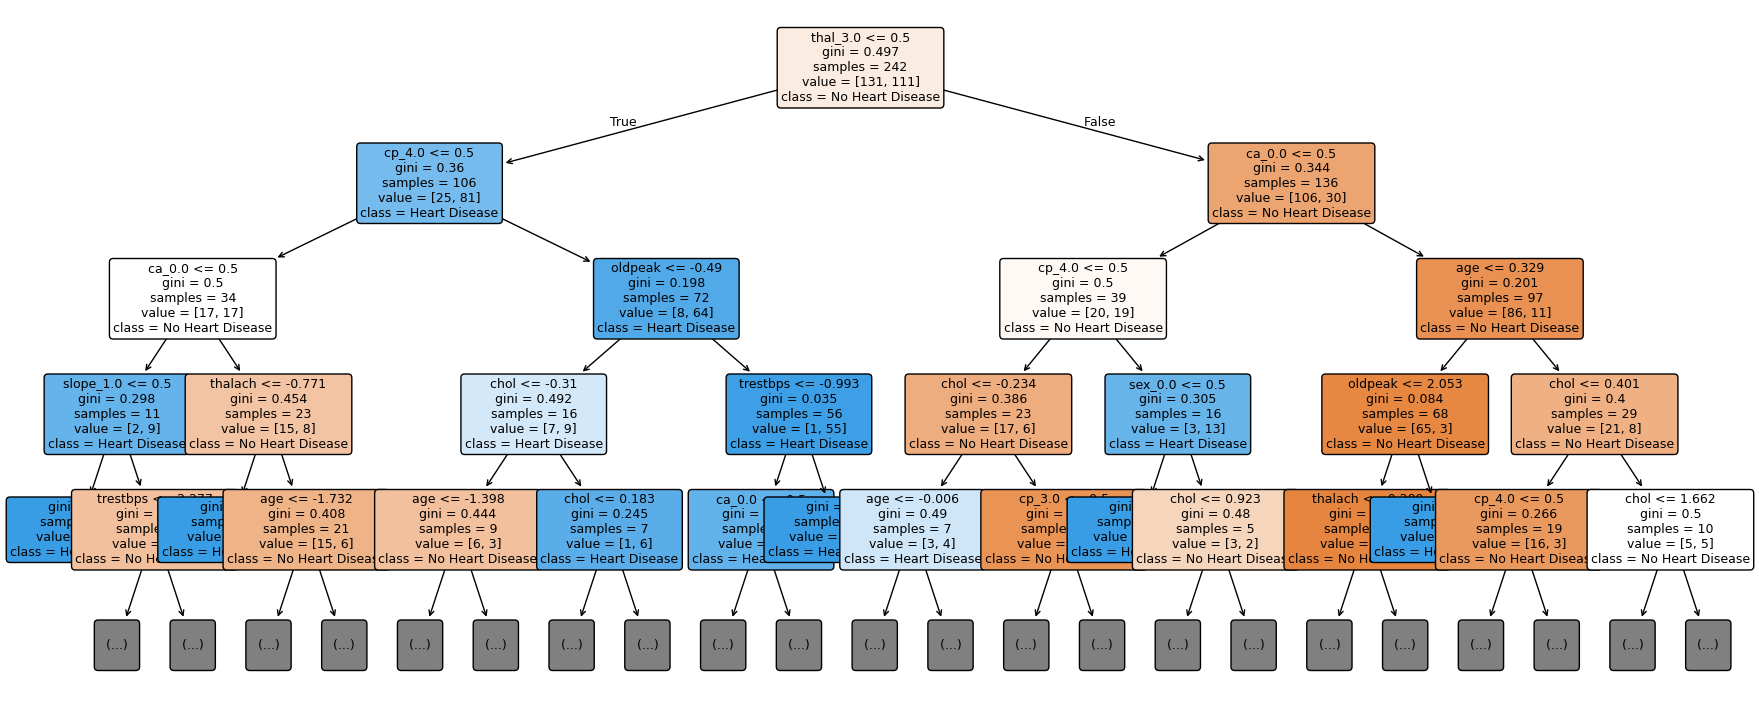

In [159]:
from sklearn.tree import plot_tree

preprocessor = DT_model.named_steps['preprocessing']
feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(DT_model.named_steps['clf'], max_depth=4, feature_names=feature_names,
          class_names=['No Heart Disease', 'Heart Disease'], filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()